# 자연어 처리 3일차 (2) — 텍스트 유사도 : 코사인 유사도 · 유클리드 거리 · 밀집 임베딩

교재 `자연어처리` 교재v1 **p.59~62 · p.66** (텍스트 유사도 · 코사인 유사도 · `cosine_similarity` · Count / TF-IDF 유사도 실습 · 밀집 표현) 를 실행하며 확인한 노트입니다.

- 함께 받은 정리 노트 `유클리드_거리_정리.md` · `PCA_차원축소_정리.md` · `tokenization-vectorization-embedding.md` · `예시코드_토큰화_벡터화_임베딩.md` 의 예제도 다시 실행해 맞춰 봤습니다 (§4~§6).
- 앞 노트 : [`bow_count_tfidf.ipynb`](./bow_count_tfidf.ipynb) · 다음 노트 : [`movie_recommendation.ipynb`](./movie_recommendation.ipynb)

$$\text{cos}(\theta) = \frac{A \cdot B}{\lVert A \rVert\,\lVert B \rVert} = \frac{\sum_i A_i B_i}{\sqrt{\sum_i A_i^2}\;\sqrt{\sum_i B_i^2}}$$

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `scikit-learn` | `CountVectorizer` · `TfidfVectorizer` · `cosine_similarity` · `PCA` | Colab 기본 포함 |
| `kiwipiepy` | Kiwi 형태소 분석기 (한글 토큰화 비교) | `pip install kiwipiepy` |
| `sentence-transformers` | **밀집 임베딩** 맛보기 — 한국어 문장 모델 `jhgan/ko-sroberta-multitask` (768차원) | `pip install sentence-transformers` — 첫 실행 때 Hugging Face 에서 모델(약 440MB)을 받는다 · **인터넷 필요** |
| `tiktoken` | OpenAI 토크나이저 토큰 수 (노트 확인용) | `pip install tiktoken` — 첫 실행 때 인코딩 파일을 받는다 |

**실행 순서** : ① 설치 셀의 `#` 를 지우고 한 번 실행 → ② 맨 위부터 **[런타임] → [모두 실행]**. GPU 는 필요 없다(문장 몇 개라 CPU 로 수 초). 받을 데이터 파일은 없다.

In [1]:
# ① 설치 (Colab · 처음 한 번)
# !pip install -q kiwipiepy sentence-transformers tiktoken

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

corpus = ['나는 배가 고프다', '내일 점심 뭐먹지', '내일 공부 해야겠다', '점심 먹고 공부해야지']

## 1. 코사인 유사도 — 손으로 vs `cosine_similarity` (교재 p.60~61)

In [4]:
def cos_sim(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))     # 내적 ÷ (길이 × 길이)

A_, B_ = np.array([3, 4]), np.array([6, 8])
print('같은 방향       :', cos_sim(A_, B_))
print('직각            :', cos_sim(A_, np.array([4, -3])))
print('정반대          :', cos_sim(A_, np.array([-3, -4])))

cv = CountVectorizer().fit(corpus)
D = cv.transform(corpus).toarray()
print('\n문장2 · 문장4 손계산 :', round(cos_sim(D[1], D[3]), 4))
print('cosine_similarity     :', cosine_similarity(D[1:2], D[3:4]).round(4))

같은 방향       : 1.0
직각            : 0.0
정반대          : -1.0

문장2 · 문장4 손계산 : 0.3333
cosine_similarity     : [[0.3333]]


In [5]:
# 교재 p.62 : Count / TF-IDF 로 만든 4 문장의 유사도 행렬
tv = TfidfVectorizer().fit(corpus)
sim_c = cosine_similarity(cv.transform(corpus))      # 희소 행렬 그대로 넣어도 된다
sim_t = cosine_similarity(tv.transform(corpus))
names = [f'문장{i+1}' for i in range(4)]
pd.concat({'Count': pd.DataFrame(sim_c, names, names).round(3),
           'TF-IDF': pd.DataFrame(sim_t, names, names).round(3)}, axis=1)

Count                      TF-IDF                     
      문장1    문장2    문장3    문장4    문장1    문장2    문장3    문장4
문장1   1.0  0.000  0.000  0.000    1.0  0.000  0.000  0.000
문장2   0.0  1.000  0.333  0.333    0.0  1.000  0.256  0.256
문장3   0.0  0.333  1.000  0.000    0.0  0.256  1.000  0.000
문장4   0.0  0.333  0.000  1.000    0.0  0.256  0.000  1.000

- 겹치는 단어가 하나도 없으면 **0** (문장1 은 누구와도 0).
- `점심` 을 함께 가진 문장2 · 4 : Count 0.333 → TF-IDF 는 `점심`(df 2)의 무게를 낮춰 더 작아진다.

### 1-1. BoW 벡터의 각도는 0~90° 뿐

In [6]:
print('Count 유사도 최솟값 :', sim_c.min(), '/ TF-IDF :', sim_t.min().round(3))
print('각도(도)            :', np.degrees(np.arccos(np.clip(sim_c, -1, 1))).round(1)[1])

Count 유사도 최솟값 : 0.0 / TF-IDF : 0.0
각도(도)            : [90.   0.  70.5 70.5]


> **📝 고친 부분 (교재 p.60 '두 벡터 사이의 각도 : 0 ~ 180', 코사인 유사도 −1 = 정반대)**
> - 일반 벡터에서는 맞다. 하지만 **Count · TF-IDF 벡터는 값이 모두 0 이상**이라 각도는 **0~90°**, 유사도는 **0~1** 만 나온다 — '정반대(−1)' 는 BoW 에서는 생기지 않는다
> - 음수가 나오는 건 학습으로 만든 **밀집 임베딩**(§5)이다

## 2. 고객응대 챗봇 예시 — 같은 뜻인데 유사도는? (교재 p.59)

In [7]:
pair = ['이 요리의 레시피를 알려줘.', '이 요리 어떻게 만드는지 알려줘.']

cvp = CountVectorizer().fit(pair)
print('Count 토큰 :', list(cvp.get_feature_names_out()))
print('Count 유사도 :', cosine_similarity(cvp.transform(pair))[0, 1].round(3))

from kiwipiepy import Kiwi
kiwi = Kiwi()
morph = lambda s: [t.form for t in kiwi.tokenize(s)]
print('\nKiwi 형태소 :', morph(pair[0]), morph(pair[1]))
cvk = CountVectorizer(tokenizer=morph, token_pattern=None, lowercase=False).fit(pair)
print('Kiwi + Count 유사도 :', cosine_similarity(cvk.transform(pair))[0, 1].round(3))

Count 토큰 : ['레시피를', '만드는지', '알려줘', '어떻게', '요리', '요리의']
Count 유사도 : 0.289



Kiwi 형태소 : ['이', '요리', '의', '레시피', '를', '알리', '어', '주', '어', '.'] ['이', '요리', '어떻', '게', '만들', '는지', '알리', '어', '주', '어', '.']
Kiwi + Count 유사도 : 0.721


`요리의` 와 `요리` 가 **다른 단어**, `이` 는 한 글자라 **버려져서** 어절 기준 유사도는 낮다. 형태소로 나누면 `이 · 요리 · 알리 · 어 · 주 · .` 가 겹쳐 올라간다 (0.289 → 0.721).
그래도 `레시피` ↔ `어떻게 만드는지` 처럼 **뜻만 같고 글자가 다른 말**은 BoW 로는 0 — 그래서 교재 p.66 의 **밀집 표현(임베딩)** 이 필요하다 (§5).

## 3. 유클리드 거리 vs 코사인 — 문장 길이의 영향

In [8]:
docs = ['점심 먹고 공부',
        '점심 먹고 공부 점심 먹고 공부',      # 같은 말을 두 번 (길이만 2배)
        '내일 공부']
M = CountVectorizer().fit_transform(docs)
print('코사인 :\n', cosine_similarity(M).round(3))
print('유클리드 :\n', euclidean_distances(M).round(3))

코사인 :
 [[1.    1.    0.408]
 [1.    1.    0.408]
 [0.408 0.408 1.   ]]
유클리드 :
 [[0.    1.732 1.732]
 [1.732 0.    3.162]
 [1.732 3.162 0.   ]]


- 같은 말을 두 번 쓴 문장 : 코사인 **1.0**(방향 같음) · 유클리드 **1.732**
- 내용이 다른 `내일 공부` : 코사인 **0.408** · 유클리드 **1.732** — 거리로는 둘이 **똑같이** 떨어져 있어 구별이 안 된다
- 길이 2배 문장 ↔ `내일 공부` 는 3.162 로 가장 멀다 → 유클리드는 **문서 길이(단어 수)** 에 끌려간다. 길이가 제각각인 텍스트에서 코사인을 쓰는 이유

In [9]:
# 유클리드_거리_정리.md 의 예제 다시 실행
a, b = np.array([1, 2]), np.array([4, 6])
print('A·B 거리               :', np.linalg.norm(b - a))
print('[3,4]·[6,8] 거리 / 코사인:', np.linalg.norm(np.array([6, 8]) - np.array([3, 4])), cos_sim(np.array([3, 4]), np.array([6, 8])))
u, v = np.array([0.6, 0.8]), np.array([0.8, -0.6])
print('길이 1 : 거리² , 2-2cos   :', round(np.linalg.norm(u - v) ** 2, 6), 2 - 2 * cos_sim(u, v))

# 길이 1 로 맞추면 '가까운 순서' 가 같은지 — TF-IDF(l2) 4 문장으로
Xt = tv.transform(corpus)
print('\nTF-IDF(l2) 에서 거리² == 2-2cos :', np.allclose(euclidean_distances(Xt) ** 2, 2 - 2 * cosine_similarity(Xt)))

A·B 거리               : 5.0
[3,4]·[6,8] 거리 / 코사인: 5.0 1.0
길이 1 : 거리² , 2-2cos   : 2.0 2.0

TF-IDF(l2) 에서 거리² == 2-2cos : True


`유클리드_거리_정리.md` 의 숫자(5.0 · 5.0 vs 1.0 · 2.0 = 2.0)와 '길이 1 이면 순위가 같다' 는 설명은 **모두 맞다.** TF-IDF 는 이미 l2 정규화돼 있어서 코사인 순서와 유클리드 순서가 같다.

## 4. 토큰화 확인 — `tokenization-vectorization-embedding.md` · `예시코드` 파트 1

In [10]:
text = '모두의 한국어 텍스트 분석 with 파이썬'
print('글자 수(공백 포함) :', len(text), '| 공백 제외 :', len(text.replace(' ', '')))

import tiktoken
for name in ['r50k_base', 'cl100k_base', 'o200k_base']:
    enc = tiktoken.get_encoding(name)
    print(f'{name:12s} 토큰 수 : {len(enc.encode(text))}')

enc = tiktoken.get_encoding('o200k_base')
print([enc.decode([i]) for i in enc.encode(text)])

글자 수(공백 포함) : 23 | 공백 제외 : 18
r50k_base    토큰 수 : 43
cl100k_base  토큰 수 : 22


o200k_base   토큰 수 : 14
['모', '두', '의', ' 한국', '어', ' �', '�', '스트', ' 분석', ' with', ' 파', '이', '�', '�']


In [11]:
for s in ['아버지가 방에 들어가신다', '아버지가 방에 들어가신다.', text]:
    print([(t.form, t.tag) for t in kiwi.tokenize(s)])

[('아버지', 'NNG'), ('가', 'JKS'), ('방', 'NNG'), ('에', 'JKB'), ('들어가', 'VV'), ('시', 'EP'), ('ᆫ다', 'EC')]
[('아버지', 'NNG'), ('가', 'JKS'), ('방', 'NNG'), ('에', 'JKB'), ('들어가', 'VV'), ('시', 'EP'), ('ᆫ다', 'EF'), ('.', 'SF')]
[('모두', 'NNG'), ('의', 'JKG'), ('한국어', 'NNP'), ('텍스트', 'NNG'), ('분석', 'NNG'), ('with', 'SL'), ('파이썬', 'NNP')]


> **📝 고친 부분 (`tokenization-vectorization-embedding.md` 3-3 · 3-4)**
> - '`모두의 한국어 텍스트 분석 with 파이썬` → **26글자, 11토큰** (GPT-4o 계열)' → 실제로는 **23글자**(공백 포함), GPT-4o 의 `o200k_base` 로 **14토큰**. 같이 받은 `예시코드` 의 `43 / 22 / 14` 가 맞다
> - Kiwi 결과의 마지막 조각은 `ᆫ다`(받침 전용 자모 `ᆫ`, U+11AB)이다 — 노트의 `ㄴ다`(U+3134)와 **다른 글자**라 문자열 비교하면 False. 마침표가 없으면 `EC`(연결 어미), 마침표가 있으면 `EF`(종결 어미)로 태그가 바뀐다

## 5. 밀집 표현 맛보기 — 문장 임베딩 (교재 p.66)

교재 p.66 : 학습으로 단어 · 문장을 **0 이 아닌 일정한 크기의 실수**로 표현. 같은 도서 제목 7개를 TF-IDF(희소)와 한국어 문장 임베딩 모델(밀집, 768차원)로 비교한다 (`예시코드` 파트 3~5).

In [12]:
titles = ['밑바닥부터 시작하는 딥러닝 1', '밑바닥부터 시작하는 딥러닝 2', '혼자 공부하는 머신러닝+딥러닝',
          'AI를 위한 필수 수학', '개발자를 위한 필수 수학', '엑셀 대신 파이썬으로 업무 자동화', 'NLP와 LLM 실전 가이드']

T = TfidfVectorizer().fit(titles)
sim_tfidf = cosine_similarity(T.transform(titles))
print('TF-IDF 토큰 :', list(T.get_feature_names_out()))

T1 = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b').fit(titles)
print('딥러닝 1 ↔ 2 : 기본', sim_tfidf[0, 1].round(3),
      '→ 한 글자 토큰 포함', cosine_similarity(T1.transform(titles))[0, 1].round(3))

TF-IDF 토큰 : ['ai를', 'llm', 'nlp와', '가이드', '개발자를', '공부하는', '대신', '딥러닝', '머신러닝', '밑바닥부터', '수학', '시작하는', '실전', '업무', '엑셀', '위한', '자동화', '파이썬으로', '필수', '혼자']
딥러닝 1 ↔ 2 : 기본 1.0 → 한 글자 토큰 포함 0.653


In [13]:
import warnings, os
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()                                   # 진행 막대 숨기기

from sentence_transformers import SentenceTransformer
model = SentenceTransformer('jhgan/ko-sroberta-multitask')        # 첫 실행 때 내려받음
emb = model.encode(titles, normalize_embeddings=True)
print('임베딩 모양 :', emb.shape, '| 0 인 칸 비율 :', f'{(emb == 0).mean():.0%}', '| 앞 5개 값 :', emb[0, :5].round(3))
sim_emb = cosine_similarity(emb)
print('유사도 최솟값 :', sim_emb.min().round(3), '(밀집 임베딩은 음수도 가능)')

임베딩 모양 : (7, 768) | 0 인 칸 비율 : 0% | 앞 5개 값 : [-0.005  0.049  0.02  -0.038 -0.014]
유사도 최솟값 : 0.209 (밀집 임베딩은 음수도 가능)


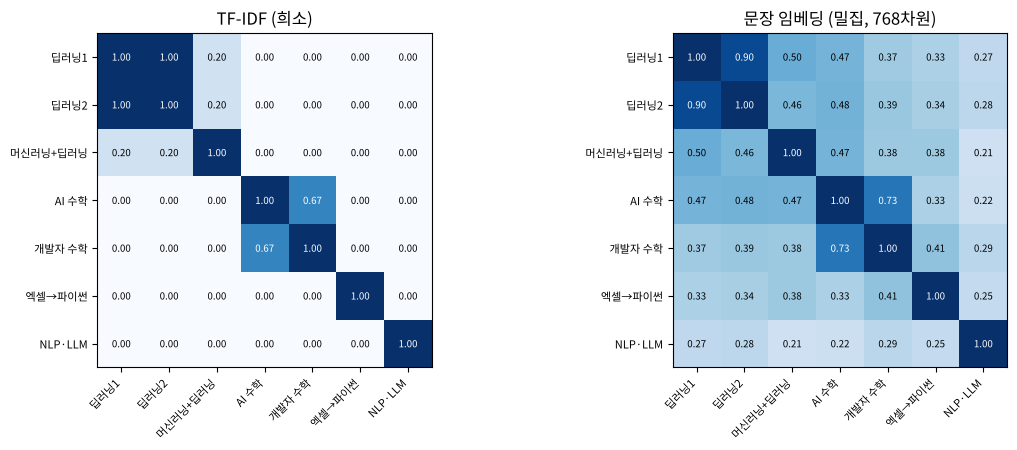

In [14]:
short = ['딥러닝1', '딥러닝2', '머신러닝+딥러닝', 'AI 수학', '개발자 수학', '엑셀→파이썬', 'NLP·LLM']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, S, name in zip(axes, [sim_tfidf, sim_emb], ['TF-IDF (희소)', '문장 임베딩 (밀집, 768차원)']):
    im = ax.imshow(S, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(7), short, rotation=45, ha='right', fontsize=8); ax.set_yticks(range(7), short, fontsize=8)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if S[i, j] > 0.6 else 'black')
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [15]:
# 새 문장으로 검색 — 제목에 '신경망' 이라는 글자가 없어도?
query = '신경망 처음 배우는 책'
q_emb = model.encode([query], normalize_embeddings=True)[0]
q_tfidf = T.transform([query])
res = pd.DataFrame({'TF-IDF': cosine_similarity(q_tfidf, T.transform(titles)).ravel().round(3),
                    '임베딩': (emb @ q_emb).round(3)}, index=titles)        # 길이 1 이라 내적 = 코사인
res.sort_values('임베딩', ascending=False)

,TF-IDF,임베딩
밑바닥부터 시작하는 딥러닝 1,0.0,0.441
밑바닥부터 시작하는 딥러닝 2,0.0,0.405
개발자를 위한 필수 수학,0.0,0.317
혼자 공부하는 머신러닝+딥러닝,0.0,0.316
엑셀 대신 파이썬으로 업무 자동화,0.0,0.275
NLP와 LLM 실전 가이드,0.0,0.260
AI를 위한 필수 수학,0.0,0.256


- TF-IDF 는 겹치는 글자가 없으면 전부 **0** — 검색이 안 된다.
- 임베딩은 0 인 칸이 없고(밀집), 글자가 달라도 뜻이 가까우면 유사도가 생긴다. 다만 **모델이 만든 점수라 항상 사람 생각과 같지는 않다** — 위 표의 순위를 직접 확인할 것.
- 딥러닝 1 ↔ 2 : TF-IDF 는 `1` · `2` 를 버려 **1.0**(완전히 같음), 임베딩은 1 보다 작은 값으로 구분한다.

> **📝 고친 부분 (`예시코드` 3-2 💡)** '한 글자 토큰을 살리면 딥러닝 1 ↔ 2 유사도가 1.0 → **0.6**' → 실행값은 **0.65**.

## 6. PCA 로 2차원에 그리기 — `PCA_차원축소_정리.md`

노트 예제 투영 : [-1.414 -1.414  1.414  1.414] | PC1 [[0.707 0.707]] | 설명된 분산 [0.8]
제목 임베딩 768 → 2차원, 설명된 분산 비율 : [0.29 0.26] 합 0.54


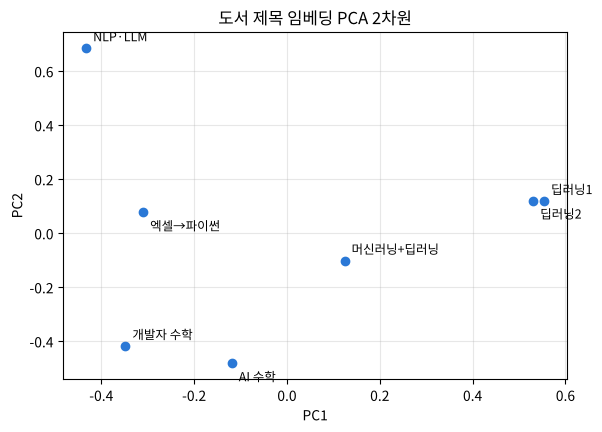

In [16]:
from sklearn.decomposition import PCA

X4 = np.array([[1, 2], [2, 1], [3, 4], [4, 3]], dtype=float)
p = PCA(n_components=1)
print('노트 예제 투영 :', p.fit_transform(X4).ravel().round(3), '| PC1', p.components_.round(3),
      '| 설명된 분산', p.explained_variance_ratio_.round(2))

pca = PCA(n_components=2)
xy = pca.fit_transform(emb)
print('제목 임베딩 768 → 2차원, 설명된 분산 비율 :', pca.explained_variance_ratio_.round(2),
      '합', pca.explained_variance_ratio_.sum().round(2))

plt.figure(figsize=(6.5, 4.5))
plt.scatter(xy[:, 0], xy[:, 1], color='#2a78d6')
for i, ((x, y), t) in enumerate(zip(xy, short)):
    plt.annotate(t, (x, y), xytext=(5, 5 if i % 2 == 0 else -13), textcoords='offset points', fontsize=9)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('도서 제목 임베딩 PCA 2차원'); plt.grid(alpha=0.3)
plt.show()

`PCA_차원축소_정리.md` 의 숫자(투영 ±1.414 · PC1 [0.707, 0.707] · 80%)는 **실행 결과와 같다.** 단 PCA 방향은 부호가 뒤집혀 나올 수도 있다(노트 끝 💡 설명대로).
점 7개를 2차원에 그리면 원래 정보의 일부만 남는다(위 '합') — 그림의 거리는 참고용, 정확한 비교는 원래 768차원의 코사인으로.

> **📝 고친 부분 (`tokenization-vectorization-embedding.md`)**
> - 5-2 'BoW 는 **등장했다/안 했다만** 보지만' → `CountVectorizer` 는 **몇 번** 나왔는지 센다(코로나 2). 등장 여부만 보려면 `binary=True`
> - 5-1 · 5-3 '토큰화(띄어쓰기 단위)' → 기본 정규식은 **한 글자 토큰을 버리고 영어를 소문자로** (`NLP와` → `nlp와`, `딥러닝 1` 의 `1` 삭제)
> - 7 '유클리드 거리는 고차원에서 **어느 각도에서 보느냐에 따라** 왜곡' → 각도에 따라 달라지는 것은 **PCA 같은 차원 축소 그림**이다. 유클리드 거리 자체의 약점은 **벡터 길이(문서 길이)의 영향**을 받는다는 것 (§3)
> - 6-1 '고차원 공간에 심는다' 와 '저차원 밀집 벡터' 가 섞여 있다 → 임베딩은 **사전 크기(수만 차원)보다는 저차원**(예 : 768 · 1,536)이고, 사람이 볼 2~3차원보다는 **고차원**이다 — 비교 대상에 따라 둘 다 맞는 말

## 정리

| 할 일 | 코드 |
|---|---|
| 유사도 행렬 | `cosine_similarity(X)` (희소 행렬 그대로 OK) |
| 한 문장 vs 전체 | `cosine_similarity(X[i], X).ravel()` |
| 거리 | `euclidean_distances(X)` — 작을수록 비슷 |
| 길이 1 벡터 | 코사인 = 내적 (`emb @ q`), 거리² = 2 − 2·코사인 |
| BoW 코사인 범위 | 0 ~ 1 (음수 없음) |

다음 : 영화 줄거리 4만 편으로 **비슷한 영화 추천** → [`movie_recommendation.ipynb`](./movie_recommendation.ipynb)